[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/TraditionalML/1_RF_proximity/RF_Proximity_Protocol.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: Traditional Machine Learning — Random-Forest Proximity Clustering

**Protocol:** `protocols/humaAI_Machine_Learning.pdf` — Human-AI condition, Approach 1 of 3 (traditional ML).
**Modeling path chosen:** example 1 of the protocol, *Composite score → Random Forest proximity → clustering*.
**Group:** Group ML-1, four students (A, B, C, D).
**Input data:** `data/EduAll_500_Applications_Dataset.csv` and the 500 application files in
`data/individual_applications/`.

We build a documented composite score (our pseudo-label), train a random forest to predict it, use the forest's proximity matrix as a distance between applicants, cluster on it, and fund segment by segment.

This notebook **is** our project report. It follows the protocol's four steps:

1. **Anchor the model's objective** — from the mission statement and the grant call: the 7 eligibility
   (hard, pass/fail) and 5 priority (soft, scored) criteria, plus the nuances we add as a group.
2. **Choose and execute a modeling path** — and why we chose it.
3. **Build and validate** — features used and excluded, fitting, the validation criterion, seed-sensitivity
   runs, and a human review of the model's output against the underlying records.
4. **Documentation and reproducibility** — full specification, which decisions are the model's and which
   are ours, the final funding list, and the output files `decision_progression.csv` and
   `final_allocation.csv`.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/TraditionalML/1_RF_proximity"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

---
## Step 1 — Anchor the model's objective

*Budget: ~13.0h for a 4-student group.*

We read the foundation's **Organization Profile** (mission and values) and the **Grant Call 2026**
(eligibility, ineligible categories, priority considerations, weighted evaluation criteria, award rules),
and the FAQ where the call refers to it.

**Mission (Organization Profile):** *"Our focus is not on academic excellence or competition, but rather on
identifying students with genuine financial need and providing them with the means to pursue their
studies."*

### 1.1 Eligibility criteria (hard, pass/fail, n = 7)

These are the call's seven *Primary Eligibility Requirements*. The last column says how we check each one in
the data, including our group's decisions where the call leaves room for interpretation.

| # | Criterion (Grant Call) | How we check it | Our decision |
|---|---|---|---|
| H1 | Non-Swiss citizen | `country_origin` | All 500 applicants are international by construction: pass. |
| H2 | Legally residing in Switzerland (valid permit B, C, F, S...; pending permits case by case) | `residency_permit`, plus the ineligible category *"Permit C and significant family financial resources"* | Permits B, C, F, S pass. Pending permits are eligible but *conditional* (the call: any award is conditional on the permit being granted). Permit C with a supporting household earning CHF 6,000/month or more fails: for us this is 'significant family resources' (about one full Swiss median net salary). |
| H3 | Accepted or enrolled at an accredited Swiss institution | `university` | All listed institutions are accredited: pass. |
| H4 | Documented genuine financial need | expected 2027/28 shortfall `monthly_expenses − family support − expected personal income`, for the months of study inside the grant period (Sep 2027 – Aug 2028) | Pass if the expected 2027/28 shortfall is positive. The months come from the completion date stated in each application file (finish Jan 2028 → 5 months, Jul 2028 → 11, later → 12). |
| H5 | Satisfactory academic standing, normally GPA ≥ 2.5 (exceptions if the reasons are explained) | `gpa`, `academic_standing` | GPA ≥ 2.5 passes. Below 2.5 we keep the applicant eligible but make any award *conditional* on the explanation and improvement plan the call asks for, checked at the interview stage. |
| H6 | Bachelor's, master's or doctoral degree, full-time or part-time | `study_level`, `study_mode` | All applicants qualify: pass. |
| H7 | No outstanding legal or immigration issues | not observable in the data | Assumed satisfied; pending permits are handled in H2. |


### 1.2 Priority criteria (soft, scored, n = 5)

| # | Criterion (Grant Call weight) | What it means for us | Variables |
|---|---|---|---|
| S1 | Financial need (40%) | The main criterion, as the mission says. We measure the shortfall relative to expenses (so that the cost of living in a given city does not decide alone) and the family's economic position. | `shortfall_ratio`, `family_household_income_chf` |
| S2 | Academic motivation & potential (25%) | Progress towards the degree and GPA, equally weighted. Academic excellence is not a primary criterion (FAQ Q11). | `courses_completed` / courses required, `gpa` |
| S3 | Personal resilience & determination (20%) | Declared resilience factors and the hardships faced (risk factors), capped at 4. | `resilience_*` (5 flags), `risk_*` (8 flags) |
| S4 | Contribution to diversity (10%) | Low-income country and first-generation status, the two diversity priorities the call names explicitly. | `gni_tier`, `risk_first_generation` |
| S5 | Alignment with EduAll values (5%) | Commitment to community, as a proxy for the values the call mentions. | `resilience_community_engagement`, `resilience_volunteer_experience` |

The call also names **priority groups**: students from low-income countries (GNI per capita below USD 3,000,
`gni_tier == 1`), first-generation students, students from under-represented regions, and students
demonstrating exceptional resilience.


### 1.3 Nuances we add as a group

* **Need is measured for the grant period, not today.** The call assesses the shortfall on the planned 2027/28 situation,
  so we use expected 2027/28 income, and we read the completion date from each application.
* **Award depth.** We prefer to fund each selected student's *full* documented shortfall for the grant period
  (net of other scholarships and of savings above a CHF 3,000 reserve) rather than spreading partial awards thinly.
  This is a value choice; we revisit what it means for the number of awards in Step 4.

❓ **Question for students:** the call estimates 140–180 awards. Is a group allowed to fund fewer, deeper awards
on the grounds that a partial award may not keep a student enrolled? What would you need to know to decide?

---
## Step 2 — Choose and execute a modeling path

*Budget: ~27.6h.*

We chose the protocol's **supervised path with a declared pseudo-label**, in its random-forest-proximity form.
Our reasons:

* the call's five weighted criteria translate naturally into an explicit composite score, which we can state in full;
* a random forest trained on that score learns *which combinations of features* produce similar scores, and its
  proximity matrix (the share of trees in which two applicants end up in the same leaf) gives us a scale-free,
  nonlinear distance that handles numeric and categorical features without manual scaling;
* clustering on that distance gives us a small number of applicant segments we can read and discuss as humans,
  instead of one opaque ranking.

In [1]:
import pathlib, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, silhouette_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering
from scipy.stats import spearmanr
SEED = 2026
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# Data: works from the course folder (protocols/agentic_mimicking_protocols/TraditionalML/<approach>/)
# and on Google Colab (upload the CSV and individual_applications.zip when asked).
CANDIDATES = [pathlib.Path("../../../../data"), pathlib.Path("../../../data"), pathlib.Path("data"), pathlib.Path(".")]
DATA = next((b for b in CANDIDATES if (b / "EduAll_500_Applications_Dataset.csv").exists()), None)
if DATA is None:
    from google.colab import files            # only reached on Colab
    print("Upload EduAll_500_Applications_Dataset.csv and individual_applications.zip")
    files.upload()
    DATA = pathlib.Path(".")
APPS = DATA / "individual_applications"
if not APPS.exists() and (DATA / "individual_applications.zip").exists():
    with zipfile.ZipFile(DATA / "individual_applications.zip") as z:
        z.extractall(DATA)

df = pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", keep_default_na=False).set_index("student_id", drop=False)
df.index.name = None
docs = {sid: (APPS / f"{sid}_application.md").read_text(encoding="utf-8") for sid in df.student_id}
print(df.shape, "| application files:", len(docs))

(500, 44) | application files: 500


In [3]:
# Quantities every approach needs, computed from the call's own rules
RISK = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
        "risk_family_emergency", "risk_language_barrier", "risk_parent_student", "risk_undocumented_status"]
RESIL = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
         "resilience_community_engagement", "resilience_overcame_adversity"]
CAP = {"Bachelor's": 8000, "Master's": 6500, "Doctoral": 5000}          # annual maximum by level
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}             # courses per degree

# Expected completion is stated in each application form; we read it from the file.
MONTH = {"January": 1, "July": 7}
def completion(text):
    m = re.search(r"\*\*Expected Completion:\*\*\s*(January|July) (\d{4})", text)
    return (int(m.group(2)), MONTH[m.group(1)]) if m else (None, None)

df["completion_year"], df["completion_month"] = zip(*[completion(docs[s]) for s in df.student_id])
# months of study inside the grant period Sep 2027 - Aug 2028 (finish Jan 2028 -> 5, Jul 2028 -> 11, later -> 12)
grant_end = (2028, 8)
def months_in_grant(y, m):
    if y is None: return 12
    if (y, m) < (2027, 9): return 0
    if (y, m) >= grant_end: return 12
    return (y - 2027) * 12 + m - 9 + 1
df["months_in_grant"] = [months_in_grant(y, m) for y, m in zip(df.completion_year, df.completion_month)]
df["months_to_completion"] = [(y - 2026) * 12 + m - 9 + 1 for y, m in zip(df.completion_year, df.completion_month)]  # from Sep 2026

df["need_2027"] = (df.monthly_expenses_chf - df.family_income_chf - df.expected_personal_income_2027_chf).clip(lower=0)
df["shortfall_ratio"] = (df.need_2027 / df.monthly_expenses_chf).clip(0, 1)
df["risk_count"] = df[RISK].sum(axis=1)
df["resil_count"] = df[RESIL].sum(axis=1)
df["progress"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["cap_period"] = df.study_level.map(CAP) * df.months_in_grant / 12
print(df.months_in_grant.value_counts().sort_index().to_dict())

{5: 50, 11: 283, 12: 167}


In [4]:

PERMIT_C_LIMIT = 6000      # "significant family financial resources" for Permit C (our threshold)
df["H1"] = np.where(df.country_origin != "Switzerland", "pass", "fail")
df["H2"] = np.select([(df.residency_permit == "C") & (df.family_household_income_chf >= PERMIT_C_LIMIT),
                      df.residency_permit == "Pending"],
                     ["fail (Permit C, household >= CHF 6,000)", "conditional (permit pending)"], "pass")
df["H3"] = np.where(df.university.str.len() > 0, "pass", "fail")
df["H4"] = np.where((df.need_2027 > 0) & (df.months_in_grant > 0), "pass", "fail (no shortfall in grant period)")
df["H5"] = np.where(df.gpa >= 2.5, "pass", "conditional")   # explanation required at interview
df["H6"] = np.where(df.study_level.isin(CAP) & df.study_mode.isin(["Full-time", "Part-time"]), "pass", "fail")
df["H7"] = "pass (assumed)"
HARD = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
df["eligible"] = ~df[HARD].apply(lambda c: c.str.startswith("fail")).any(axis=1)
df["conditional"] = df[HARD].apply(lambda c: c.str.startswith("conditional")).any(axis=1)
summary = pd.DataFrame({h: df[h].value_counts() for h in HARD}).fillna(0).astype(int)
display(summary)
print(f"eligible: {df.eligible.sum()} of {len(df)} (of which conditional: {(df.eligible & df.conditional).sum()})")

,H1,H2,H3,H4,H5,H6,H7
conditional,0,0,0,0,81,0,0
conditional (permit pending),0,16,0,0,0,0,0
"fail (Permit C, household >= CHF 6,000)",0,20,0,0,0,0,0
fail (no shortfall in grant period),0,0,0,76,0,0,0
pass,500,464,500,424,419,500,0
pass (assumed),0,0,0,0,0,0,500


eligible: 413 of 500 (of which conditional: 74)


In [5]:
# Award request for the grant period: shortfall x months, minus other scholarships and savings, capped
# Savings: savings above a CHF 3,000 emergency reserve are spread evenly until graduation; the share falling in the grant period is deducted
df["scholarship_period"] = df.external_scholarship_amount_chf * df.months_in_grant / 12
df["savings_counted"] = ((df.savings_chf - 3000).clip(lower=0) * np.minimum(1, df.months_in_grant / df.months_to_completion)).round()
df["request"] = (df.need_2027 * df.months_in_grant - df.scholarship_period - df.savings_counted).clip(lower=0)
df["request"] = np.minimum(df.request, df.cap_period).round()
print(f"eligible applicants with a positive request: {(df.eligible & (df.request > 0)).sum()}; "
      f"their total request: CHF {df.loc[df.eligible, 'request'].sum():,.0f} vs budget CHF 500,000")

eligible applicants with a positive request: 400; their total request: CHF 2,182,247 vs budget CHF 500,000


---
## Step 3 — Build and validate

*Budget: ~81.2h — the bulk of the phase.*

### 3.1 Feature set and deliberate exclusions

**Used (17 features):** the need, academic, resilience, diversity and values variables of Step 1, plus the
variables that shape how a shortfall arises: `need_2027`, `shortfall_ratio`, `family_household_income_chf`,
`savings_chf`, `external_scholarship_amount_chf`, `gpa`, `progress`, `risk_count`, `resil_count`, `gni_tier`,
`risk_first_generation`, `resilience_community_engagement`, `resilience_volunteer_experience`, `dependent_children`,
`is_part_time`, `is_doctoral`, `permit_F_S_or_pending`.

**Excluded, and why:**
* `gender`, `age`, `country_origin`: no role in the call's criteria; using them could import bias the call forbids
  (Equal Opportunity Policy). Country enters only through `gni_tier`, which the call itself uses.
* `university`, `field_of_study`: no stated role; field of study is exactly the kind of unintended proxy the
  protocol warns about.
* `average_grade` (duplicates GPA), `publications` (academic excellence is not a criterion), `application_date`.
* The written statements: this approach uses only structured data. We use the texts in Step 3.6 to *check* the model.

❓ **Question for students:** excluding `field_of_study` protects against one proxy, but could other included
variables (for example `need_2027`, which depends on city rents and tuition) still carry information about the
institution or field? How would you test that?

In [6]:
df["is_part_time"] = (df.study_mode == "Part-time").astype(int)
df["is_doctoral"] = (df.study_level == "Doctoral").astype(int)
df["permit_F_S_or_pending"] = df.residency_permit.isin(["F", "S", "Pending"]).astype(int)
FEATURES = ["need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf", "external_scholarship_amount_chf",
            "gpa", "progress", "risk_count", "resil_count", "gni_tier", "risk_first_generation",
            "resilience_community_engagement", "resilience_volunteer_experience", "dependent_children",
            "is_part_time", "is_doctoral", "permit_F_S_or_pending"]
E = df[df.eligible].copy()          # the model is fitted on eligible applicants only
X = E[FEATURES].astype(float)
print("eligible applicants used for modelling:", len(E))

eligible applicants used for modelling: 413


### 3.2 The pseudo-label (our model's "ground truth"), stated in full

All percentiles (`pct`) are computed among eligible applicants and lie between 0 and 1.

$$\text{composite} = 0.40\,N + 0.25\,A + 0.20\,R + 0.10\,D + 0.05\,V$$

* $N = 0.7\,\text{pct}(\text{shortfall\_ratio}) + 0.3\,(1-\text{pct}(\text{family\_household\_income}))$
* $A = 0.5\,\text{pct}(\text{progress}) + 0.5\,\text{pct}(\text{gpa})$
* $R = 0.6\,\text{resil\_count}/5 + 0.4\,\min(\text{risk\_count},4)/4$
* $D = 0.6\,[\text{gni\_tier}=1] + 0.4\,\text{first\_generation}$
* $V = 0.5\,\text{community\_engagement} + 0.5\,\text{volunteer\_experience}$

The weights are the call's own (40/25/20/10/5); the sub-weights are our group decision.

In [7]:
pct = lambda s: s.rank(pct=True)
N = 0.7 * pct(E.shortfall_ratio) + 0.3 * (1 - pct(E.family_household_income_chf))
A = 0.5 * pct(E.progress) + 0.5 * pct(E.gpa)
R = 0.6 * E.resil_count / 5 + 0.4 * E.risk_count.clip(upper=4) / 4
D = 0.6 * (E.gni_tier == 1) + 0.4 * E.risk_first_generation
V = 0.5 * E.resilience_community_engagement + 0.5 * E.resilience_volunteer_experience
E["composite"] = 0.40 * N + 0.25 * A + 0.20 * R + 0.10 * D + 0.05 * V
E["composite"].describe().round(3)

count    413.000
mean       0.497
std        0.144
min        0.138
25%        0.389
50%        0.501
75%        0.605
max        0.858
Name: composite, dtype: float64

### 3.3 Fit the random forest, with 5-fold cross-validation

The forest predicts the composite from the 17 features. Cross-validation tells us whether it has learnt the
construct (out-of-fold R²), so that its leaf structure — and therefore the proximity matrix — reflects it.

5-fold CV: R2 = 0.853, MAE = 0.0444 (composite sd = 0.144)


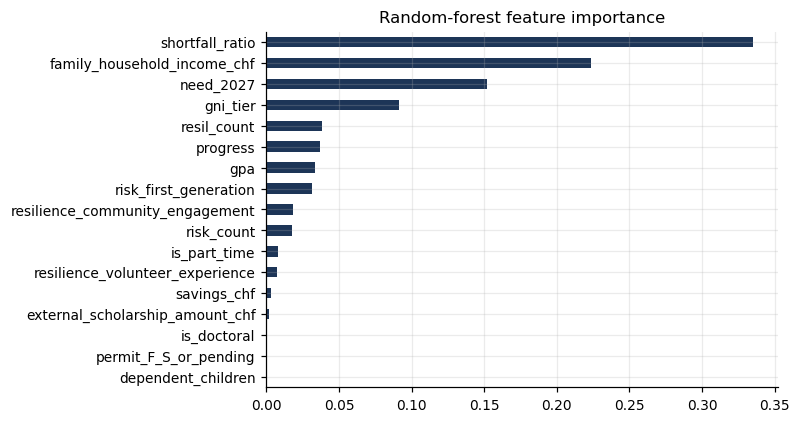

In [8]:
rf_params = dict(n_estimators=500, min_samples_leaf=5, max_features=0.5, n_jobs=-1)
cv = KFold(5, shuffle=True, random_state=SEED)
oof = cross_val_predict(RandomForestRegressor(random_state=SEED, **rf_params), X, E.composite, cv=cv)
print(f"5-fold CV: R2 = {r2_score(E.composite, oof):.3f}, MAE = {mean_absolute_error(E.composite, oof):.4f} "
      f"(composite sd = {E.composite.std():.3f})")
rf = RandomForestRegressor(random_state=SEED, **rf_params).fit(X, E.composite)
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
ax = imp.plot.barh(figsize=(6, 4.2), color="#1d3557"); ax.set_title("Random-forest feature importance"); plt.show()

**What we see (A, B).** Out-of-fold R² = 0.85 (MAE 0.044 on a score with sd 0.144). The forest reproduces our composite well from the 17 features, so its leaf structure reflects the construct we defined. The importance plot is dominated by `shortfall_ratio` and `gni_tier`, followed by GPA, progress and household income. That is what the 40% need weight and the tier-1 component of diversity should produce.

**Caution (C).** A high R² means the forest has learnt *our* formula. It says nothing about whether the formula is right. Validation here means "the model is faithful to the declared objective", not "the model finds the deserving students".

### 3.4 Proximity matrix and clustering; number of clusters by silhouette

Proximity(i, j) = share of the 500 trees in which applicants i and j land in the same terminal leaf;
distance = 1 − proximity. We cluster with average-linkage agglomerative clustering on this precomputed distance and
choose the number of clusters *k* with the silhouette score (it works on any distance matrix).

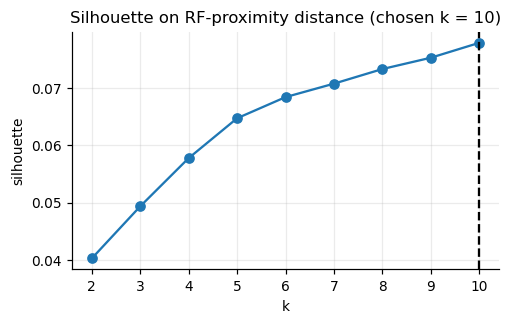

{2: 0.04, 3: 0.049, 4: 0.058, 5: 0.065, 6: 0.068, 7: 0.071, 8: 0.073, 9: 0.075, 10: 0.078}
cluster sizes: {0: 72, 1: 50, 2: 70, 3: 34, 4: 45, 5: 47, 6: 25, 7: 31, 8: 26, 9: 13}


In [9]:
def proximity_distance(model, X):
    leaves = model.apply(X)                               # (n, trees)
    n, t = leaves.shape
    P = np.zeros((n, n))
    for j in range(t):
        P += leaves[:, [j]] == leaves[:, j]
    return 1 - P / t

Dist = proximity_distance(rf, X)
ks = range(2, 11)
sil = {}
for k in ks:
    lab = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average").fit_predict(Dist)
    sil[k] = silhouette_score(Dist, lab, metric="precomputed")
K = max(sil, key=sil.get)
plt.figure(figsize=(5, 2.8)); plt.plot(list(sil), list(sil.values()), "o-"); plt.axvline(K, ls="--", c="k")
plt.xlabel("k"); plt.ylabel("silhouette"); plt.title(f"Silhouette on RF-proximity distance (chosen k = {K})"); plt.show()
E["cluster"] = AgglomerativeClustering(n_clusters=K, metric="precomputed", linkage="average").fit_predict(Dist)
print({k: round(v, 3) for k, v in sil.items()}); print("cluster sizes:", E.cluster.value_counts().sort_index().to_dict())

**What we see.** The silhouette is very low for every k (0.04 to 0.08) and rises steadily, without a peak. The rule "choose the k with the highest silhouette" therefore picks the upper end of the range we tried (k = 10). Our honest reading (D): the applicants do not fall into natural, well-separated groups. They form a continuum, and the clustering *cuts* it into ten pieces. We keep k = 10 because the segments are stable across seeds (next step) and small enough (13 to 72 applicants) to read. But we will not describe them as "types" of applicants.

❓ **Question for students:** if the silhouette never peaks, is "choose k by silhouette" still a meaningful rule? Which alternative would you defend: a fixed k you can review by hand, the elbow, stability across seeds, or dropping clustering altogether and ranking on the forest score?

### 3.5 Seed-sensitivity runs

The forest is random. We refit it with five different seeds and compare (a) the cluster assignments (adjusted Rand
index, ARI) and (b) the forest's predicted scores (Spearman correlation).

In [10]:
runs = {}
for s in [1, 7, 42, 2026, 31415]:
    m = RandomForestRegressor(random_state=s, **rf_params).fit(X, E.composite)
    lab = AgglomerativeClustering(n_clusters=K, metric="precomputed", linkage="average").fit_predict(proximity_distance(m, X))
    runs[s] = (lab, m.predict(X))
seeds = list(runs)
ari = pd.DataFrame([[adjusted_rand_score(runs[a][0], runs[b][0]) for b in seeds] for a in seeds], index=seeds, columns=seeds)
rho = pd.DataFrame([[spearmanr(runs[a][1], runs[b][1])[0] for b in seeds] for a in seeds], index=seeds, columns=seeds)
print("ARI between cluster assignments (seeds):"); display(ari.round(2))
print("Spearman between predicted scores (seeds):"); display(rho.round(3))

ARI between cluster assignments (seeds):


,1,7,42,2026,31415
1,1.00,0.88,0.85,0.88,0.89
7,0.88,1.00,0.88,0.92,0.94
42,0.85,0.88,1.00,0.85,0.88
2026,0.88,0.92,0.85,1.00,0.94
31415,0.89,0.94,0.88,0.94,1.00


Spearman between predicted scores (seeds):


,1,7,42,2026,31415
1,1.000,0.999,0.999,1.000,1.000
7,0.999,1.000,0.999,0.999,0.999
42,0.999,0.999,1.000,0.999,0.999
2026,1.000,0.999,0.999,1.000,1.000
31415,1.000,0.999,0.999,1.000,1.000


**What we see.** The predicted scores barely move between seeds (Spearman ≥ 0.999). The cluster assignments move more, but stay similar (ARI 0.85 to 0.94). Part of the segment boundaries is therefore an artefact of the random seed. Because we fund segment by segment, a seed change could move an applicant near a boundary into a different segment. We record this as a known weakness; the final within-segment order uses the composite, which does not depend on the seed.

### 3.6 What do the clusters mean? Profiles, and a check for unintended proxies

In [11]:
prof = E.groupby("cluster").agg(n=("composite", "size"), composite=("composite", "mean"),
        shortfall_ratio=("shortfall_ratio", "median"), need_2027=("need_2027", "median"),
        household=("family_household_income_chf", "median"), gpa=("gpa", "median"),
        progress=("progress", "median"), resil=("resil_count", "mean"), risk=("risk_count", "mean"),
        tier1=("gni_tier", lambda s: (s == 1).mean() * 100), part_time=("is_part_time", lambda s: s.mean() * 100),
        doctoral=("is_doctoral", lambda s: s.mean() * 100)).sort_values("composite", ascending=False).round(2)
display(prof)

def cramers_v(a, b):
    t = pd.crosstab(a, b).values
    from scipy.stats import chi2_contingency
    chi2 = chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.sum() * (min(t.shape) - 1)))
for col in ["field_of_study", "university", "study_level", "gender", "geographic_region"]:
    print(f"Cramer's V (cluster vs {col}): {cramers_v(E.cluster, E[col]):.2f}")

,n,composite,shortfall_ratio,need_2027,household,gpa,progress,resil,risk,tier1,part_time,doctoral
cluster,,,,,,,,,,,,
5,47,0.68,0.92,1960.0,680.0,2.92,0.33,2.38,1.89,100.00,0.00,12.77
8,26,0.67,0.73,1471.0,795.0,3.14,0.35,3.35,2.31,96.15,0.00,11.54
3,34,0.62,0.82,1780.0,1225.0,3.10,0.25,2.68,2.26,100.00,5.88,17.65
7,31,0.55,0.79,1620.0,1050.0,3.12,0.25,2.55,0.71,100.00,9.68,9.68
0,72,0.50,0.77,1674.0,1660.0,3.18,0.33,2.25,1.29,0.00,9.72,18.06
2,70,0.50,0.45,879.0,860.0,2.91,0.26,3.03,1.57,100.00,27.14,4.29
9,13,0.44,0.52,1114.0,1140.0,3.04,0.33,2.46,1.69,0.00,0.00,23.08
6,25,0.41,0.41,864.0,2580.0,3.02,0.25,2.32,1.32,100.00,48.00,0.00
4,45,0.36,0.45,989.0,3880.0,2.93,0.33,2.67,1.38,0.00,22.22,6.67


Cramer's V (cluster vs field_of_study): 0.25
Cramer's V (cluster vs university): 0.17
Cramer's V (cluster vs study_level): 0.18
Cramer's V (cluster vs gender): 0.13
Cramer's V (cluster vs geographic_region): 0.41


**What the segments mean (the four of us read the table together).**

* The top four segments (5, 8, 3, 7; 138 applicants) are almost entirely tier-1 applicants with high shortfall ratios (0.73 to 0.92) and low household income. They differ mainly in resilience/risk (segment 8 has the most resilience factors) and in savings.
* Segment 0 (72 applicants) has a high shortfall ratio too (0.77), but **no** tier-1 applicants. It ranks fifth: diversity (10%) separates it from segments with similar need.
* The bottom segments (6, 4, 1) combine low shortfall ratios with household incomes of CHF 2,600 to 5,000, and many part-time students.

**Proxy check.** Cramér's V with `geographic_region` is 0.41, the highest of the five: region follows almost directly from GNI tier, which the call *asks* us to use. Field of study (0.25) and university (0.17) are weaker. Gender (0.13) shows no meaningful association. The segments are not driven by field or gender. They *are* strongly geographic, through a criterion the call names explicitly.

### 3.7 Human review of a sample of records

For each cluster we read two applications: the one closest to the cluster's median composite score and a random one.
We check whether the cluster label tracks the intended construct (need first, then academic progress,
resilience and diversity) or something else.

In [12]:
rng = np.random.default_rng(SEED)
def excerpt(sid, n=650):
    t = docs[sid]
    i = t.find("## Section 4")
    body = t[i:].split("\n", 3)[-1] if i >= 0 else t
    return re.sub(r"\s+", " ", body)[:n]
for c in prof.index:
    members = E[E.cluster == c]
    typical = (members.composite - members.composite.median()).abs().idxmin()
    other = rng.choice([s for s in members.index if s != typical]) if len(members) > 1 else typical
    for sid in dict.fromkeys([typical, other]):
        r = E.loc[sid]
        print(f"[cluster {c}] {sid} | {r.study_level}, {r.study_mode}, tier {r.gni_tier}, GPA {r.gpa} | "
              f"shortfall ratio {r.shortfall_ratio:.2f}, need CHF {r.need_2027:,.0f}/month, household CHF "
              f"{r.family_household_income_chf:,}, savings CHF {r.savings_chf:,} | composite {r.composite:.3f}")
        print("   ", excerpt(sid), "...\n")

[cluster 5] STU000065 | Master's, Full-time, tier 1, GPA 2.89 | shortfall ratio 0.88, need CHF 1,892/month, household CHF 850, savings CHF 0 | composite 0.681
     My situation in numbers: my costs are CHF 2,142 per month, and my brother sends me CHF 250. I don't have a job now. I have a scholarship of CHF 6,030 per year from a Bangladeshi engineering association, which I want to declare clearly. With this scholarship, my real gap is smaller than the CHF 1,892 in the form, but it is still big. My brother is an electrician in Chittagong; his household lives on about CHF 850 per month. He also supports our mother. I also have to be honest that my grades are average, GPA 2.89. I had polio as a child, and my left leg is weak. The EPFL campus is big, and lab courses with long standing hours are physically h ...

[cluster 5] STU000414 | Bachelor's, Full-time, tier 1, GPA 2.12 | shortfall ratio 0.89, need CHF 1,899/month, household CHF 930, savings CHF 0 | composite 0.610
     I have four sem

**Human review (each of us read five of the twenty excerpts in full).** In most cases the segment matches the file: high-need, tier-1 applicants in the top segments, and low-shortfall part-time applicants with working spouses or parents in segment 1. Three cases show what the structured data cannot see:

* **STU000164** (segment 0): the file says the supervisor's grant pays a salary from January 2028. The real need in the grant period is about 4 months, not 12, but the model, like the CSV, assumes 12.
* **STU000270** (segment 7): the permit is up for renewal and the migration office asks for proof of means. The CSV says permit B; the file suggests a pending situation, relevant to H2/H7.
* **STU000065** (segment 5): the file declares an external scholarship (CHF 6,030/year) and the request rule deducts it correctly. Our *need* variables, however, still treat the full shortfall as unmet. The composite overstates this applicant's need somewhat.

We flag these three for the interview stage. We do not change the model: correcting individual records by hand inside the model would make it irreproducible.

❓ **Question for students:** the protocol asks for a human review of model output against the records. When a review finds that the *data* (not the model) is wrong for an applicant, should the group correct the data and refit, override the decision for that applicant, or only flag it? What does each option do to reproducibility and to fairness towards applicants nobody read?

---
## Step 4 — Documentation, and from model output to a funding list

*Budget: ~40.6h.*

### 4.1 Translating the clusters into a funding order (our decision)

The model gives us segments and a score. **How** those become a funding list is our decision. We fund **segment by
segment**, starting with the segment with the highest mean composite. Within a segment, applicants are ordered by their
composite score. In our **first draft**, each funded applicant receives their full grant-period request (100%), down to a minimum of CHF
1,000, until the CHF 500,000 is spent. A segment, not only a score, decides the order: two applicants with similar
scores in different segments can be treated differently. We accept this, because the segments are what we reviewed
and can defend.

In [13]:
cluster_rank = {c: i for i, c in enumerate(prof.index)}            # 0 = highest mean composite
df["cluster"] = E.cluster.reindex(df.index)
df["composite"] = E.composite.reindex(df.index)
df["rf_score"] = pd.Series(rf.predict(X), index=E.index).reindex(df.index)
df["cluster_priority"] = df.cluster.map(cluster_rank)

In [14]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# segments in order of mean composite; within a segment by composite; full request; minimum CHF 1,000
BUDGET, FRACTION, MIN_AWARD = 500_000, 1.0, 1000
order = df[df.eligible & (df.request > 0)].sort_values(["cluster_priority", "composite"], ascending=[True, False]).index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 82 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 6,098


**Draft 1.** Funding full requests segment by segment spends the CHF 500,000 on **82 applicants** (mean award CHF 6,098), all from the top three segments. That is well below the call's 140–180 estimate.

In [15]:
df["award_draft1"] = df.award          # keep the first draft in the decision path
print("draft 1, funded by segment:", df.loc[df.award > 0, "cluster_priority"].value_counts().sort_index().to_dict())
print("draft 1, funded by GNI tier:", df.loc[df.award > 0, "gni_tier"].value_counts().sort_index().to_dict(),
      "| eligible by GNI tier:", df.loc[df.eligible, "gni_tier"].value_counts().sort_index().to_dict())

draft 1, funded by segment: {0.0: 47, 1.0: 26, 2.0: 9}
draft 1, funded by GNI tier: {1: 81, 3: 1} | eligible by GNI tier: {1: 232, 2: 120, 3: 61}


**Group discussion of draft 1, and our revision.**

* Draft 1 funds 81 tier-1 applicants and one tier-3 applicant, out of an eligible pool of 232 / 120 / 61 (tiers 1 / 2 / 3). No applicant from segment 0 (high need, not tier 1) is reached.
* B and D still prefer full awards (our nuance in 1.3). A and C point out that the call expects 140–180 awards, and that 82 awards leave many applicants with shortfall ratios above 0.75 unfunded.
* **Decision (3 against 1, D dissenting):** keep the segment order, but award **70% of each request**. In the interview we will tell recipients plainly that the award covers about 70% of their documented gap. We do *not* change the order to bring in segment 0: that would mean overriding the weights we declared in Step 1.

We keep draft 1 in the output file (`award_draft1`), so that the decision path shows both versions.

❓ **Question for students:** moving from 100% to 70% raises the number of awards by about 40%, while the *order* stays the same. Is a smaller award to more students a modelling decision, a value decision, or both? Who should make it: the analysts, the selection committee, or the foundation's board?

In [16]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# REVISED: same order; 70% of each request; minimum CHF 1,000
BUDGET, FRACTION, MIN_AWARD = 500_000, 0.7, 1000
order = df[df.eligible & (df.request > 0)].sort_values(["cluster_priority", "composite"], ascending=[True, False]).index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 118 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 4,237


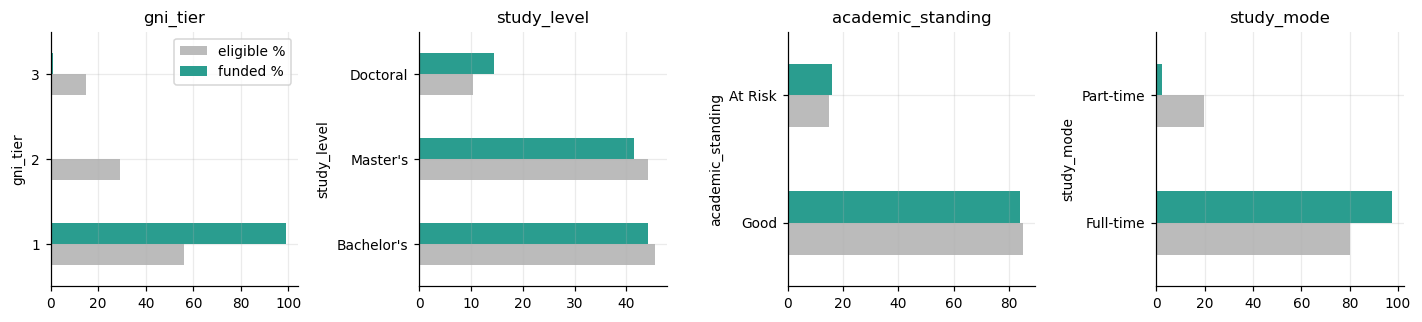

median shortfall ratio  funded: 0.86 | eligible not funded: 0.50


In [17]:
# Who is funded? Composition of the final list against the eligible pool
def share(col):
    e = df.loc[df.eligible, col].astype(str).value_counts(normalize=True).mul(100)
    f = df.loc[df.award > 0, col].astype(str).value_counts(normalize=True).mul(100)
    return pd.DataFrame({"eligible %": e, "funded %": f}).fillna(0).round(1)
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axs, ["gni_tier", "study_level", "academic_standing", "study_mode"]):
    share(col).plot.barh(ax=ax, color=["#bbbbbb", "#2a9d8f"], legend=(col == "gni_tier"))
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("median shortfall ratio  funded: %.2f | eligible not funded: %.2f" % (
    df.loc[df.award > 0, "shortfall_ratio"].median(), df.loc[df.eligible & (df.award == 0), "shortfall_ratio"].median()))

**Final list.** 118 awards, CHF 500,000. 117 of the 118 recipients are tier 1. The median shortfall ratio is 0.86 among recipients and 0.50 among eligible applicants not funded. The list serves the call's top priority (need) and its low-income-country priority. Students from tier-2/3 countries with high shortfall ratios (segment 0) receive nothing. This follows from the segment-first rule and from the size of the budget, and it is the main point we would raise with the selection committee.

In [18]:
# Output files: the full decision path (all 500) and the final allocation (funded only)
df["status"] = np.select([df.award > 0, ~df.eligible], [np.where(df.conditional, "funded (conditional)", "funded"),
                         "not eligible"], "eligible, not funded")
df["reason"] = np.select([df.award > 0, ~df.eligible], ["segment " + df.cluster_priority.astype("Int64").astype(str) + " (rank " + df.funding_rank.astype("Int64").astype(str) + "), 70% of request", "failed: " + df[HARD].apply(lambda r: ", ".join(h for h in HARD if r[h].startswith("fail")), axis=1)], "eligible; budget exhausted before this segment/rank")
INPUTS = ["student_id", "study_level", "study_mode", "residency_permit", "gni_tier", "geographic_region", "gpa",
          "academic_standing", "need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf",
          "external_scholarship_amount_chf", "risk_count", "resil_count", "completion_year", "completion_month",
          "months_in_grant"]
STEPS = HARD + ["eligible", "conditional"] + ["cluster", "cluster_priority", "composite", "rf_score", "award_draft1"] + ["request", "funding_rank", "award", "status", "reason"]
decision_progression = df[INPUTS + STEPS]
decision_progression.to_csv("decision_progression.csv", index=False)
final = decision_progression[decision_progression.award > 0].sort_values("funding_rank")
final.to_csv("final_allocation.csv", index=False)
print("decision_progression.csv:", decision_progression.shape, "| final_allocation.csv:", final.shape,
      f"| total CHF {final.award.sum():,.0f}")
final.head(8)

decision_progression.csv: (500, 37) | final_allocation.csv: (118, 37) | total CHF 500,000


,student_id,study_level,study_mode,residency_permit,gni_tier,geographic_region,gpa,academic_standing,need_2027,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,risk_count,resil_count,...,H5,H6,H7,eligible,conditional,cluster,cluster_priority,composite,rf_score,award_draft1,request,funding_rank,award,status,reason
STU000335,STU000335,Doctoral,Full-time,Pending,1,South Asia,3.63,Good,2263,0.930127,840,7717,0,5,3,...,pass,pass,pass (assumed),True,True,5.0,0.0,0.857605,0.770742,4583.0,4583.0,1.0,3208.0,funded (conditional),"segment 0 (rank 1), 70% of request"
STU000274,STU000274,Bachelor's,Full-time,Pending,1,Sub-Saharan Africa,3.13,Good,1960,0.937799,540,2375,5151,4,3,...,pass,pass,pass (assumed),True,True,5.0,0.0,0.853507,0.764630,7333.0,7333.0,2.0,5133.0,funded (conditional),"segment 0 (rank 2), 70% of request"
STU000142,STU000142,Doctoral,Full-time,B,1,South Asia,3.41,Good,1903,0.926936,910,9675,0,3,4,...,pass,pass,pass (assumed),True,False,5.0,0.0,0.821030,0.758565,5000.0,5000.0,3.0,3500.0,funded,"segment 0 (rank 3), 70% of request"
STU000024,STU000024,Bachelor's,Full-time,B,1,Middle East/North Africa,3.02,Good,2214,0.940527,550,0,0,2,3,...,pass,pass,pass (assumed),True,False,5.0,0.0,0.798562,0.746781,7333.0,7333.0,4.0,5133.0,funded,"segment 0 (rank 4), 70% of request"
STU000072,STU000072,Master's,Full-time,Pending,1,South Asia,3.37,Good,1567,0.902130,800,0,7872,3,3,...,pass,pass,pass (assumed),True,True,5.0,0.0,0.798465,0.737878,5958.0,5958.0,5.0,4170.0,funded (conditional),"segment 0 (rank 5), 70% of request"
STU000198,STU000198,Doctoral,Full-time,B,1,South Asia,3.67,Good,2116,0.967978,430,14388,0,1,3,...,pass,pass,pass (assumed),True,False,5.0,0.0,0.795511,0.724917,4583.0,4583.0,6.0,3208.0,funded,"segment 0 (rank 6), 70% of request"
STU000324,STU000324,Bachelor's,Full-time,B,1,Sub-Saharan Africa,4.00,Good,1747,0.925808,850,13340,0,1,3,...,pass,pass,pass (assumed),True,False,5.0,0.0,0.780081,0.746484,7333.0,7333.0,7.0,5133.0,funded,"segment 0 (rank 7), 70% of request"
STU000380,STU000380,Bachelor's,Full-time,B,1,South Asia,2.95,Good,1682,0.903330,770,0,0,2,4,...,pass,pass,pass (assumed),True,False,5.0,0.0,0.774741,0.731164,7333.0,7333.0,8.0,5133.0,funded,"segment 0 (rank 8), 70% of request"


### 4.2 Which decisions are the model's, and which are ours

| Decision | Made by | How |
|---|---|---|
| Which criteria count and with which weights (pseudo-label) | Humans (us) | Step 1 and 3.2, from the call's 40/25/20/10/5 |
| Eligibility thresholds (Permit C CHF 6,000; GPA exception conditional) | Humans (us) | Step 1.1 |
| Which features the model sees | Humans (us) | Step 3.1 |
| How applicants are grouped (proximity, segments) | Model | random forest + clustering; k by silhouette |
| Order of segments and order within a segment | Humans (us) | mean composite; composite score |
| Award size (draft 1: full request; final: 70% of request, CHF 1,000 minimum) | Humans (us) | Step 4.1, revised after reading draft 1 |
| Conditional awards (pending permit, GPA < 2.5) | Humans (us) | confirmed at interview, else passed down the list |


### 4.3 Reproducibility

Re-running this notebook on the same CSV and application files reproduces the same output exactly (fixed seed
`SEED = 2026`). The seed-sensitivity runs in Step 3.5 show how much depends on that seed. Specification in full:
pseudo-label (Step 3.2), features (3.1), forest parameters (`n_estimators=500, min_samples_leaf=5,
max_features=0.5`), distance (1 − proximity), clustering (average linkage, k by silhouette over 2–10), funding rule (4.1, as revised: 70% of request).

### 4.4 Summary of our decision path

1. 500 applicants → **413 eligible** (76 with no shortfall in the grant period; 20 Permit C with household ≥ CHF 6,000). 74 of the eligible are conditional (16 pending permits, the rest GPA < 2.5).
2. Pseudo-label = our composite of the call's five criteria. The random forest learns it with CV R² = 0.85.
3. RF proximity → 10 segments. Silhouette is low (weak structure), but segments are fairly stable across seeds (ARI 0.85–0.94).
4. Segments funded in order of mean composite. Draft 1 (full requests): 82 awards. **Final (70% of request): 118 awards, CHF 500,000.**
5. Three records flagged for the interview stage, where the file contradicts the structured data (STU000164, STU000270, STU000065).

Output files: `decision_progression.csv` (all 500 applicants, every step) and `final_allocation.csv` (funded applicants, in funding order).